# EUR/USD: volatility clustering, ARCH and GARCH

This analysis examines dependence in daily exchange-rate movements and their
changing volatility. ACFs, ARCH/GARCH models and rolling/EWMA comparisons
connect volatility clustering with conditional variance and forecast uncertainty.

The analysis uses **1,249 daily observations for 2021–2025**. EUR/USD is quoted
in **US dollars per euro**; log changes are expressed in **percent**.

Data Sources:

- [Federal Reserve Board, H.10 historical euro rates](https://www.federalreserve.gov/releases/h10/hist/dat00_eu.htm):
  daily New York noon buying rates, not seasonally adjusted.
- [FRED DEXUSEU](https://fred.stlouisfed.org/series/DEXUSEU): equivalent series and definition.


## Environment setup

**Colab:** the setup expects the complete `Notebooks` folder in **My Drive**,
with its subfolders and CSV files. Running the cell below mounts Google Drive
and requests access.
**Local Jupyter:** the same folder structure supports local execution.
`NOTEBOOKS_ROOT` specifies a different location when needed.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "Time_Series"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: Time_Series


## Libraries

In [2]:
from inspect import signature
import importlib.util
import subprocess
import sys

# Install the additional volatility-model library only when missing.
if importlib.util.find_spec("arch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "arch>=8.0,<9"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.stats.diagnostic import het_arch
from arch import arch_model
from arch.univariate import Normal
from IPython.display import display

## Data

In [3]:
levels = pd.read_csv(DATA_DIR / "daily_eur_usd.csv", index_col="date", parse_dates=True)
if not levels.index.is_unique or not levels.index.is_monotonic_increasing:
    raise ValueError("Inspect duplicate or unordered quotation dates.")
if levels.isna().any().any() or not levels["usd_per_eur"].gt(0).all():
    raise ValueError("Inspect missing or non-positive exchange rates.")
display(levels.head().round(4))

,usd_per_eur
date,
2009-12-01,1.5100
2009-12-02,1.5059
2009-12-03,1.5081
2009-12-04,1.4885
2009-12-07,1.4820


## Log changes and squared demeaned changes

For the USD-per-EUR quotation $S_t$, log changes and squared demeaned changes are

$$r_t=100\log(S_t/S_{t-1}),\qquad q_t=(r_t-\bar r)^2.$$

A positive change means euro appreciation against the dollar. These are
exchange-rate changes, rather than investment returns including interest.
One lag means one **observed quotation**; weekends and other dates without
quotations are omitted, without interpolation or inserted zero changes.

Squared changes measure movement size in **squared percentage-point units**.
They are noisy proxies for conditional variance when the conditional mean is
close to zero. Volatility is the conditional **standard deviation**, rather
than its square. Subtracting the sample mean is descriptive and does not
estimate a changing conditional mean.


In [4]:
all_changes = 100 * np.log(levels["usd_per_eur"]).diff()
returns = all_changes.loc["2021":"2025"].rename("FX log change")
if returns.isna().any() or returns.empty:
    raise ValueError("Missing analysis changes: inspect the quotation base.")
squared_returns = ((returns - returns.mean()) ** 2).rename("Squared demeaned change")
series = {"FX log changes": returns, "Squared demeaned changes": squared_returns}
print(f"Sample: {len(returns)} quotations, {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}")
display(pd.concat([returns, squared_returns], axis=1).head().round(4))

Sample: 1249 quotations, 2021-01-04 to 2025-12-31


,FX log change,Squared demeaned change
date,,
2021-01-04,0.1960,0.0397
2021-01-05,0.3340,0.1138
2021-01-06,-0.0407,0.0014
2021-01-07,-0.2036,0.0401
2021-01-08,-0.1060,0.0106


## Daily changes and volatility clustering


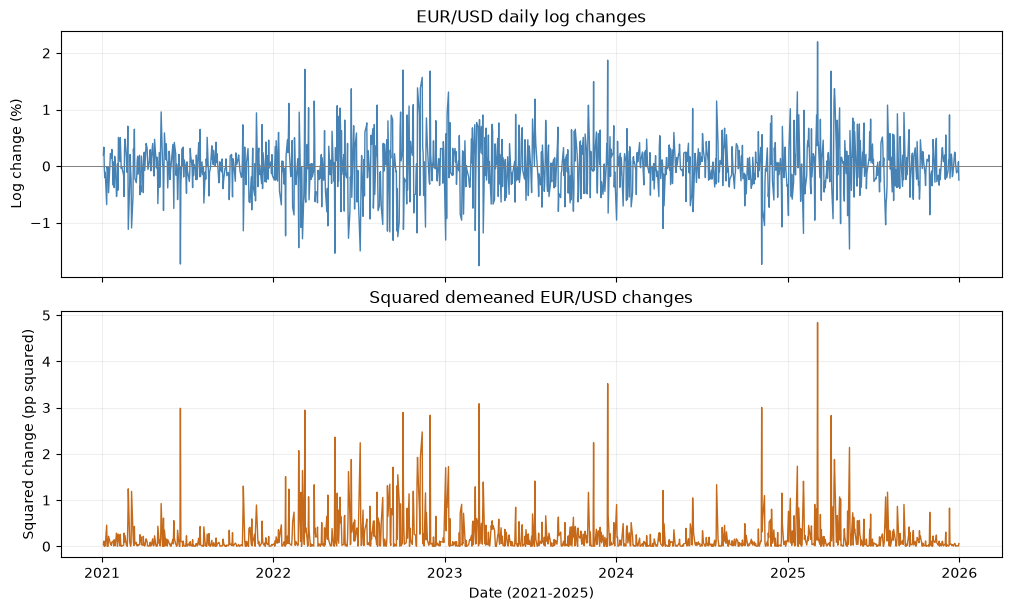

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
for ax, values, title, unit, color in zip(
    axes, [returns, squared_returns], ["EUR/USD daily log changes", "Squared demeaned EUR/USD changes"],
    ["Log change (%)", "Squared change (pp squared)"], ["steelblue", "#C66A19"]
):
    ax.plot(values.index, values, color=color, linewidth=1)
    ax.set(title=title, ylabel=unit)
    ax.grid(alpha=0.2)
axes[0].axhline(0, color="grey", linewidth=0.7)
axes[1].set_xlabel("Date (2021-2025)")
plt.show()

Large appreciations and depreciations can cluster even when signed changes
have little autocorrelation. Squaring removes the sign and highlights movement
magnitudes; an individual squared change is not the conditional variance itself.


## Distribution and the Normal benchmark

The histogram compares observed changes with a Normal density fitted using
the sample mean and standard deviation. Excess kurtosis describes the
**unconditional** distribution, rather than shocks conditional on past information.


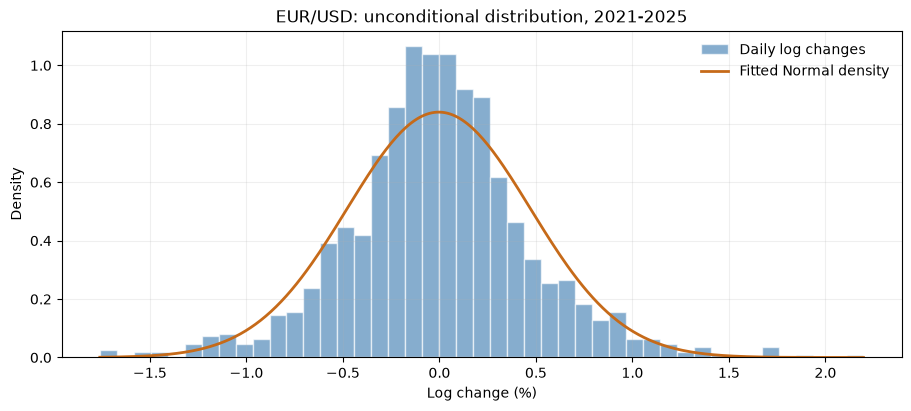

,Sample moment
Mean (%),-0.0033
Sample SD (%),0.4750
Skewness,0.1501
Excess kurtosis,1.5934


In [6]:
grid = np.linspace(returns.min(), returns.max(), 300)
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.hist(returns, bins=45, density=True, alpha=0.65, color="steelblue", edgecolor="white", label="Daily log changes")
ax.plot(grid, stats.norm.pdf(grid, loc=returns.mean(), scale=returns.std(ddof=1)),
        color="#C66A19", linewidth=2, label="Fitted Normal density")
ax.set(xlabel="Log change (%)", ylabel="Density", title="EUR/USD: unconditional distribution, 2021-2025")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
plt.show()
display(pd.Series({"Mean (%)": returns.mean(), "Sample SD (%)": returns.std(ddof=1),
                   "Skewness": stats.skew(returns, bias=False),
                   "Excess kurtosis": stats.kurtosis(returns, fisher=True, bias=False)}, name="Sample moment").round(4).to_frame())

## ACF of changes and squared changes


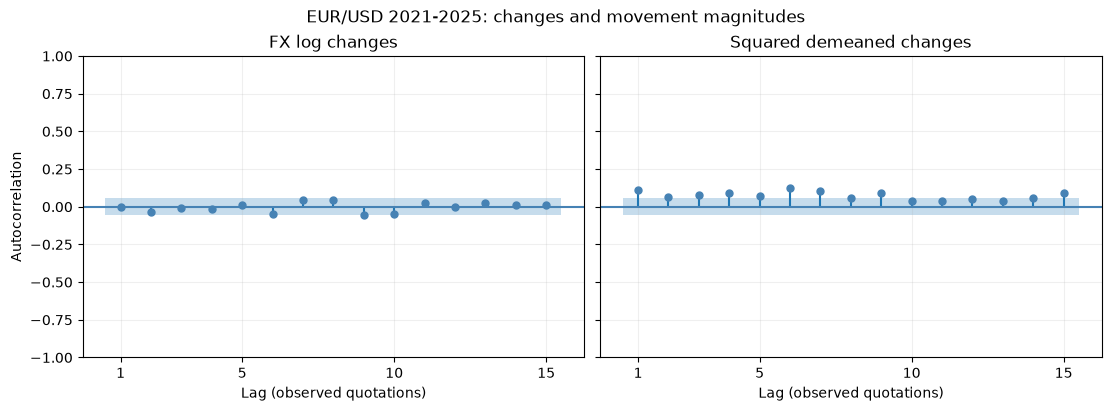

In [7]:
MAX_ACF_LAG = 15
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
for ax, (name, values) in zip(axes, series.items()):
    plot_acf(values, lags=MAX_ACF_LAG, zero=False, alpha=0.05,
             bartlett_confint=False, ax=ax, color="steelblue")
    ax.set(title=name, xlabel="Lag (observed quotations)")
    ax.set_xticks([1, 5, 10, 15])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Autocorrelation")
fig.suptitle("EUR/USD 2021-2025: changes and movement magnitudes")
plt.show()

### Reading the ACFs

The squared-change ACF reveals persistence in magnitudes that may be absent
from signed changes. The bands are approximate **pointwise white-noise bands**;
they are not simultaneous bounds, and changing volatility can affect their calibration.

## AR models and lag selection

Each series $z_t\in\{r_t,q_t\}$ has the AR specification

$$z_t=c+\phi_1z_{t-1}+\cdots+\phi_pz_{t-p}+e_t.$$

The analysis compares AR orders **0–10**, including an intercept. A common hold-back of
10 observations gives every candidate the same **1,239 estimation observations**.
AR(0) is an intercept-only model.

For maximised conditional log likelihood $\ell$ and $K$ parameters, including
innovation variance,

$$\mathrm{AIC}=-2\ell+2K,\qquad \mathrm{BIC}=-2\ell+K\log n.$$

Smaller values are preferred. BIC penalises additional parameters more strongly.
Criterion comparisons concern the **same dependent variable**: criterion values for changes
and squared changes are not directly comparable. The Gaussian conditional
likelihood is a working approximation here.


In [8]:
MAX_AR_LAG = 10
CRITERIA = ["AIC", "BIC"]
models, rows = {}, []
for name, values in series.items():
    models[name] = {}
    for p in range(MAX_AR_LAG + 1):
        fit = AutoReg(values.to_numpy(), lags=p, trend="c", hold_back=MAX_AR_LAG).fit()
        models[name][p] = fit
        rows.append({"Series": name, "AR order": p, "AIC": fit.aic, "BIC": fit.bic,
                     "Estimation n": int(fit.nobs)})
selection = pd.DataFrame(rows)
selected_orders = pd.DataFrame({
    criterion: {name: min(fits, key=lambda p: getattr(fits[p], criterion.lower()))
                for name, fits in models.items()} for criterion in CRITERIA
})
selected_orders.index.name = "Series"
display(selection.pivot(index="AR order", columns="Series", values=CRITERIA).round(3))
display(selected_orders.rename_axis(columns="Criterion: selected AR order"))

AIC                                     BIC  \
Series   FX log changes Squared demeaned changes FX log changes   
AR order                                                          
0              1680.404                 1417.384       1690.648   
1              1682.403                 1404.107       1697.769   
2              1682.855                 1402.466       1703.344   
3              1684.732                 1399.541       1710.342   
4              1686.514                 1394.226       1717.246   
5              1688.390                 1393.455       1724.244   
6              1687.463                 1382.470       1728.439   
7              1686.835                 1378.144       1732.934   
8              1686.928                 1379.609       1738.149   
9              1685.516                 1377.034       1741.859   
10             1684.612                 1378.953       1746.076   

                                   
Series   Squared demeaned changes  
AR order                           
0                        1427.628  
1                        1419.473  
2                        1422.954  
3                        1425.152  
4                        1424.958  
5                        1429.309  
6                        1423.447  
7                        1424.243  
8                        1430.830  
9                        1433.377  
10                       1440.417

Criterion: selected AR order,AIC,BIC
Series,,
FX log changes,0,0
Squared demeaned changes,9,1


## Selected AR models

The tables report each distinct selected model on the same estimation sample. They
test coefficients against zero and use **HAC standard errors with five lags**,
Bartlett weights, a sample-size correction and approximate $t$ inference.
Intervals condition on the selected model; they omit lag-selection uncertainty.


In [9]:
# Estimate each distinct selected model once, with the same dependent-variable sample.
HAC_LAGS = 5
selected_fits, rows = {}, []
for name, values in series.items():
    for p in sorted(set(selected_orders.loc[name])):
        criteria = ", ".join(c for c in CRITERIA if selected_orders.loc[name, c] == p)
        fit = AutoReg(values.to_numpy(), lags=p, trend="c", hold_back=MAX_AR_LAG).fit(
            cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS, "use_correction": True}, use_t=True)
        selected_fits[(name, p)] = fit
        interval = np.asarray(fit.conf_int())
        for j, term in enumerate(["Intercept"] + [f"Lag {lag}" for lag in range(1, p + 1)]):
            rows.append({"Series": name, "Model": f"AR({p}) ({criteria})", "Term": term,
                         "Estimate": fit.params[j], "HAC SE": fit.bse[j], "p-value": fit.pvalues[j],
                         "95% lower": interval[j, 0], "95% upper": interval[j, 1]})
coefficients = pd.DataFrame(rows).set_index(["Series", "Model", "Term"])
with pd.option_context("display.float_format", "{:.4g}".format):
    display(coefficients)

Estimate  HAC SE  \
Series                   Model            Term                          
FX log changes           AR(0) (AIC, BIC) Intercept -0.002459  0.0131   
Squared demeaned changes AR(1) (BIC)      Intercept    0.2014 0.01532   
                                          Lag 1        0.1107 0.03474   
                         AR(9) (AIC)      Intercept    0.1202 0.01815   
                                          Lag 1       0.07803 0.02969   
                                          Lag 2       0.02507 0.02672   
                                          Lag 3       0.03642 0.03218   
                                          Lag 4       0.06119 0.03484   
                                          Lag 5       0.03077 0.03554   
                                          Lag 6       0.09271  0.0341   
                                          Lag 7       0.06794 0.03667   
                                          Lag 8       0.01602 0.02633   
                                          Lag 9        0.0607 0.03193   

                                                      p-value  95% lower  \
Series                   Model            Term                             
FX log changes           AR(0) (AIC, BIC) Intercept    0.8512   -0.02817   
Squared demeaned changes AR(1) (BIC)      Intercept 4.642e-37     0.1714   
                                          Lag 1      0.001473    0.04256   
                         AR(9) (AIC)      Intercept 5.339e-11    0.08457   
                                          Lag 1        0.0087    0.01977   
                                          Lag 2        0.3483   -0.02736   
                                          Lag 3        0.2579   -0.02671   
                                          Lag 4       0.07931  -0.007169   
                                          Lag 5        0.3868   -0.03896   
                                          Lag 6      0.006651     0.0258   
                                          Lag 7       0.06416  -0.004003   
                                          Lag 8        0.5431   -0.03564   
                                          Lag 9        0.0575  -0.001936   

                                                     95% upper  
Series                   Model            Term                  
FX log changes           AR(0) (AIC, BIC) Intercept    0.02325  
Squared demeaned changes AR(1) (BIC)      Intercept     0.2315  
                                          Lag 1         0.1789  
                         AR(9) (AIC)      Intercept     0.1558  
                                          Lag 1         0.1363  
                                          Lag 2         0.0775  
                                          Lag 3        0.09954  
                                          Lag 4         0.1295  
                                          Lag 5         0.1005  
                                          Lag 6         0.1596  
                                          Lag 7         0.1399  
                                          Lag 8        0.06767  
                                          Lag 9         0.1233

### Interpreting the AR comparison

**Both criteria select AR(0) for signed changes.** For squared demeaned changes,
**AIC selects AR(9), while BIC selects AR(1)**. The squared-change intercept
is in squared percentage-point units; lag coefficients are dimensionless.
Only lags 1 and 6 in the AR(9) are significant at 5% using the reported HAC
inference. Model selection does not imply that every included lag is significant
or identify a uniquely correct population order.

AR(0) selection does not establish independence, a random-walk exchange rate
or market efficiency. It means that neither criterion prefers lagged signed
changes among these candidates. Dependence in squared changes is consistent
with volatility clustering, without establishing profitable currency forecasts.

The squared-change AR models a noisy variance proxy and can produce negative
predictions. ARCH and GARCH instead model conditional variance directly.
HAC does not repair an unsuitable mean model or endogeneity, and in-sample
fit does not establish out-of-sample accuracy.


## Gaussian ARCH(1): conditional and unconditional moments

The change decomposes as $r_t=\mu+\epsilon_t$, with

$$\epsilon_t=\sigma_tz_t,\qquad z_t\stackrel{iid}{\sim}N(0,1),\qquad
\sigma_t^2=\omega+\alpha\epsilon_{t-1}^2.$$

The shock $z_t$ is independent of past information. The restrictions $\omega>0$
and $\alpha\ge0$ ensure positive conditional variance.

### Second moment

For a stationary solution with finite variance, iterated expectations give

$$m_2=E[\epsilon_t^2]=E[\sigma_t^2]=\omega+\alpha m_2
\quad\Longrightarrow\quad m_2=\frac{\omega}{1-\alpha},\qquad \alpha<1.$$

### Fourth moment and kurtosis

Since $E[z_t^4]=3$, a finite stationary fourth moment satisfies

$$m_4=E[\epsilon_t^4]=3E[\sigma_t^4]
=3\omega^2+6\omega\alpha m_2+3\alpha^2m_4.$$

Solving and dividing by $m_2^2$ gives

$$m_4=\frac{3\omega^2(1+\alpha)}{(1-\alpha)(1-3\alpha^2)},\qquad
\kappa=3\frac{1-\alpha^2}{1-3\alpha^2}.$$

Finite kurtosis requires **$3\alpha^2<1$**, a stronger condition than finite
variance. For $1/\sqrt3\le\alpha<1$, variance is finite but the fourth moment
is not. Kurtosis equals 3 at $\alpha=0$ and exceeds 3 for
$0<\alpha<1/\sqrt3$. Thus Gaussian **conditional** shocks can generate
unconditional fat tails. Excess kurtosis is $\kappa-3$.


## Testing for ARCH effects

A constant-mean fit gives residuals $\widehat\epsilon_t=r_t-\bar r$.
The auxiliary regression relates their squares to a constant and **10 lagged
squares**, with the lag choice fixed before the result is examined. The hypotheses are

$$H_0:\gamma_1=\cdots=\gamma_{10}=0,\qquad
H_1:\text{at least one lag coefficient differs from zero}.$$

The ARCH LM statistic has an approximate $\chi^2_{10}$ null reference.
The sample-size correction allows for one fitted mean parameter. Rejection
indicates ARCH-type dependence at these lags; it does not identify the correct
GARCH order or shock distribution.


In [10]:
ARCH_TEST_LAGS = 10
# Select the supported result format without suppressing statistical warnings.
ARCH_TEST_OPTIONS = {"result_object": False} if "result_object" in signature(het_arch).parameters else {}
mean_residuals = returns - returns.mean()
lm_stat, lm_pvalue, _, _ = het_arch(mean_residuals, nlags=ARCH_TEST_LAGS, ddof=1, **ARCH_TEST_OPTIONS)
arch_test = pd.DataFrame({"LM statistic": [lm_stat], "Reference df": [ARCH_TEST_LAGS],
                          "p-value": [lm_pvalue],
                          "Decision at 5%": ["Reject H0" if lm_pvalue < 0.05 else "Do not reject H0"]},
                         index=["Constant-mean residuals"])
display(arch_test.style.format({"LM statistic": "{:.4f}", "p-value": "{:.3g}"}))

,LM statistic,Reference df,p-value,Decision at 5%
Constant-mean residuals,57.0291,10,1.32e-08,Reject H0


The p-value is about **1.32e-8**, so the test rejects at 5%. This motivates modelling
conditional variance, while keeping dependence in movement magnitudes distinct
from predictability of appreciation or depreciation.


## ARCH and GARCH models

All candidates use the same constant mean and Gaussian conditional likelihood:

$$r_t=\mu+\epsilon_t,\qquad
\sigma_t^2=\omega+\sum_{i=1}^{p}\alpha_i\epsilon_{t-i}^2
+\sum_{j=1}^{q}\beta_j\sigma_{t-j}^2.$$

Here **$p$ counts squared-shock lags and $q$ counts variance lags**, following
the `arch` convention. ARCH(1) has $(p,q)=(1,0)$. The candidates are constant variance,
ARCH(1), ARCH(2), and GARCH(1,1), (1,2), (2,1), (2,2), all fitted to **1,249 observations**.
Their AIC/BIC values are comparable; those from the earlier squared-change
regressions use a different dependent variable and likelihood.

Changes are already in percent. A conditional SD of 0.5 means 0.5 percentage
points of daily log change. Every candidate uses the same initial variance
from the **50 quotations before 2021**. The optimiser status records convergence for each fit.

Variance coefficients are nonnegative. Finite unconditional variance requires
$\sum\alpha_i+\sum\beta_j<1$ and then equals
$\omega/(1-\sum\alpha_i-\sum\beta_j)$. This condition does not by itself
establish a finite fourth moment.


In [11]:
PRE_SAMPLE_LENGTH = 50
pre_sample = all_changes.loc[:"2020-12-31"].dropna().tail(PRE_SAMPLE_LENGTH)
BACKCAST = float(pre_sample.var(ddof=0))
VARIANCE_ORDERS = [(0, 0), (1, 0), (2, 0), (1, 1), (1, 2), (2, 1), (2, 2)]

def model_label(order):
    p, q = order
    return "Constant variance" if p == 0 else f"ARCH({p})" if q == 0 else f"GARCH({p},{q})"

def fit_variance_model(values, order, initial_variance=BACKCAST, starting_values=None):
    p, q = order
    model = arch_model(values, mean="Constant", vol="Constant" if p == 0 else "GARCH",
                       p=max(1, p), q=q, dist="normal", rescale=False, hold_back=0)
    result = model.fit(disp="off", update_freq=0, cov_type="robust", backcast=initial_variance,
                       starting_values=starting_values, show_warning=False,
                       options={"maxiter": 2000, "ftol": 1e-9})
    if result.convergence_flag != 0:
        raise RuntimeError(str(result.optimization_result.message))
    return result

variance_fits, rows = {}, []
for order in VARIANCE_ORDERS:
    fit = fit_variance_model(returns, order)
    variance_fits[order] = fit
    rows.append({"Model": model_label(order), "AIC": fit.aic, "BIC": fit.bic,
                 "Log likelihood": fit.loglikelihood, "n": fit.nobs,
                 "Converged": fit.convergence_flag == 0})
variance_selection = pd.DataFrame(rows).set_index("Model")
selected_variance_orders = {criterion: min(variance_fits, key=lambda order: getattr(variance_fits[order], criterion.lower()))
                            for criterion in ["AIC", "BIC"]}
display(variance_selection.round(3))
display(pd.Series({criterion: model_label(order) for criterion, order in selected_variance_orders.items()},
                  name="Selected variance model").to_frame())

,AIC,BIC,Log likelihood,n,Converged
Model,,,,,
Constant variance,1687.836,1698.096,-841.918,1249,True
ARCH(1),1668.085,1683.475,-831.042,1249,True
ARCH(2),1659.996,1680.516,-825.998,1249,True
"GARCH(1,1)",1574.823,1595.343,-783.412,1249,True
"GARCH(1,2)",1576.077,1601.727,-783.038,1249,True
"GARCH(2,1)",1576.823,1602.474,-783.412,1249,True
"GARCH(2,2)",1569.677,1600.458,-778.839,1249,True


,Selected variance model
AIC,"GARCH(2,2)"
BIC,"GARCH(1,1)"


### Comparing specifications

**AIC selects GARCH(2,2); BIC selects GARCH(1,1).** They balance fit and
complexity differently. ARCH(1) connects the estimates with the moment derivation.
Reported standard errors use the robust quasi-likelihood covariance. The
Normal-reference intervals are approximate, particularly near zero-parameter
boundaries, and omit order-selection uncertainty.


In [12]:
reported_orders = sorted({(1, 0), *selected_variance_orders.values()})
rows, moment_rows = [], []
for order in reported_orders:
    fit = variance_fits[order]
    interval = fit.conf_int()
    for term in fit.params.index:
        rows.append({"Model": model_label(order), "Parameter": term,
                     "Estimate": fit.params[term], "Robust SE": fit.std_err[term],
                     "95% lower": interval.loc[term].iloc[0], "95% upper": interval.loc[term].iloc[1]})
    persistence = float(fit.params.filter(regex=r"^(alpha|beta)\[").sum())
    moment_rows.append({"Model": model_label(order), "Sum alpha + beta": persistence,
                        "Long-run variance (pp squared)": fit.params["omega"] / (1 - persistence) if persistence < 1 else np.nan})
parameter_comparison = pd.DataFrame(rows).set_index(["Model", "Parameter"])
display(parameter_comparison.round(5))
display(pd.DataFrame(moment_rows).set_index("Model").round(5))
alpha_arch1 = float(variance_fits[(1, 0)].params["alpha[1]"])
arch1_kurtosis = 3 * (1 - alpha_arch1**2) / (1 - 3 * alpha_arch1**2) if 3 * alpha_arch1**2 < 1 else np.inf
print(f"ARCH(1): alpha = {alpha_arch1:.4f}; implied unconditional kurtosis = {arch1_kurtosis:.4f}")

Estimate  Robust SE  95% lower  95% upper
Model      Parameter                                           
ARCH(1)    mu         -0.00525    0.01304   -0.03080    0.02030
           omega       0.19779    0.01398    0.17038    0.22519
           alpha[1]    0.12364    0.03679    0.05153    0.19574
GARCH(1,1) mu         -0.00946    0.01203   -0.03305    0.01413
           omega       0.00274    0.00168   -0.00055    0.00603
           alpha[1]    0.04020    0.01126    0.01814    0.06226
           beta[1]     0.94763    0.01559    0.91708    0.97819
GARCH(2,2) mu         -0.00859    0.01533   -0.03864    0.02146
           omega       0.00376    0.00229   -0.00073    0.00826
           alpha[1]    0.06508    0.01593    0.03385    0.09631
           alpha[2]    0.00655    0.02377   -0.04003    0.05314
           beta[1]     0.00000    0.23394   -0.45852    0.45852
           beta[2]     0.91218    0.22459    0.47200    1.35237

,Sum alpha + beta,Long-run variance (pp squared)
Model,,
ARCH(1),0.12364,0.22569
"GARCH(1,1)",0.98784,0.22545
"GARCH(2,2)",0.98382,0.23249


ARCH(1): alpha = 0.1236; implied unconditional kurtosis = 3.0961


## Conditional volatility and persistence

In GARCH(1,1), $\alpha$ measures the response to the latest squared shock and
$\beta$ carries forward past variance. Their sum measures variance-shock
persistence, rather than autocorrelation in signed changes. Persistent variance
does not imply predictable appreciation or depreciation.

The fitted ARCH(1) has $\alpha<1/\sqrt3$, so its Gaussian fourth moment is
finite. This does not establish the true process's moments or model adequacy.

The selected GARCH paths appear in **separate panels with the same scale**.
A further panel shows **AIC-selected minus BIC-selected SD** in percentage
points, making differences visible when the paths are nearly identical.


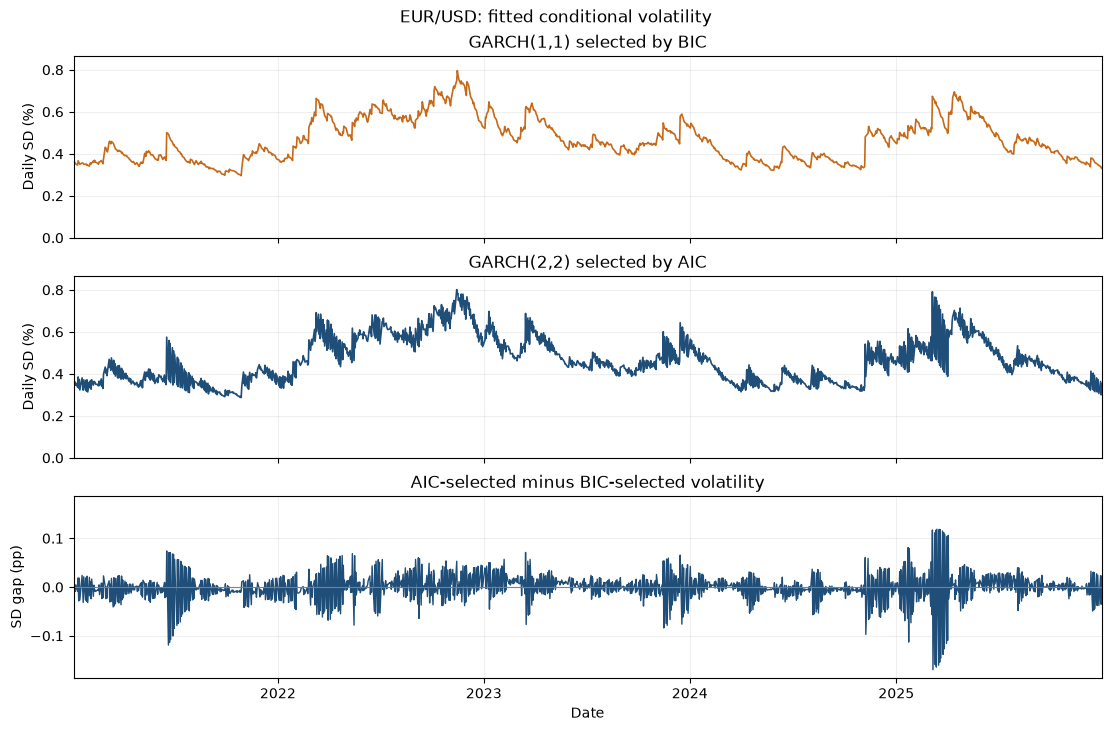

In [13]:
selected_plot_orders = sorted(set(selected_variance_orders.values()))
show_gap = len(selected_plot_orders) > 1
fig, axes = plt.subplots(len(selected_plot_orders) + int(show_gap), 1,
                         figsize=(11, 2.6 * len(selected_plot_orders) + 2.0 * int(show_gap)),
                         sharex=True, squeeze=False, constrained_layout=True)
axes = axes.ravel()
common_max = max(variance_fits[order].conditional_volatility.max() for order in selected_plot_orders)
for ax, order in zip(axes, selected_plot_orders):
    criteria = ", ".join(c for c, chosen in selected_variance_orders.items() if chosen == order)
    color = "#1F4E79" if order == selected_variance_orders["AIC"] else "#C66A19"
    ax.plot(returns.index, variance_fits[order].conditional_volatility, color=color, linewidth=1.2)
    ax.set(title=f"{model_label(order)} selected by {criteria}", ylabel="Daily SD (%)",
           ylim=(0, 1.08 * common_max))
if show_gap:
    difference = (variance_fits[selected_variance_orders["AIC"]].conditional_volatility
                  - variance_fits[selected_variance_orders["BIC"]].conditional_volatility)
    axes[-1].plot(returns.index, difference, color="#1F4E79", linewidth=1)
    axes[-1].axhline(0, color="grey", linewidth=0.8)
    bound = 1.1 * difference.abs().max()
    axes[-1].set(title="AIC-selected minus BIC-selected volatility", ylabel="SD gap (pp)",
                 ylim=(-bound, bound))
for ax in axes:
    ax.set_xlim(returns.index[0], returns.index[-1])
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Date")
fig.suptitle("EUR/USD: fitted conditional volatility")
plt.show()


## Standardised-residual diagnostics

Standardising each selected model's residuals gives $\widehat z_t=\widehat\epsilon_t/\widehat\sigma_t$.
The ACF of $\widehat z_t^2$ and the repeated **10-lag ARCH test** assess remaining dependence.
Remaining dependence in these squares suggests that variance dynamics have
not been fully captured.

The post-fit chi-square reference is approximate: residuals, parameters and
orders were estimated on these data. Non-rejection does not validate every
model assumption.


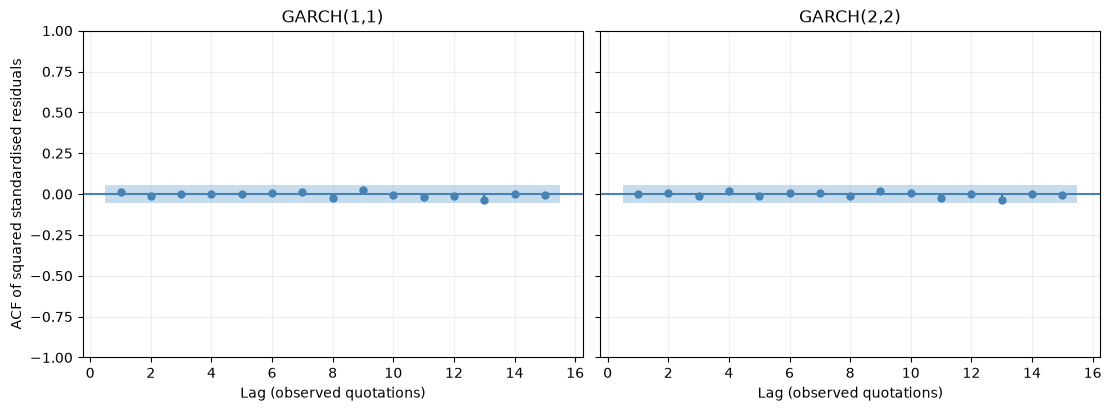

,ARCH LM,p-value
Model,,
"GARCH(1,1)",2.6218,0.989
"GARCH(2,2)",1.8876,0.997


In [14]:
orders = sorted(set(selected_variance_orders.values()))
fig, axes = plt.subplots(1, len(orders), figsize=(11, 4), sharey=True, squeeze=False, constrained_layout=True)
diagnostic_rows = []
for ax, order in zip(axes.ravel(), orders):
    fit = variance_fits[order]
    standardised = fit.std_resid.dropna()
    plot_acf(standardised**2, lags=15, zero=False, alpha=0.05,
             bartlett_confint=False, ax=ax, color="steelblue")
    ax.set(title=model_label(order), xlabel="Lag (observed quotations)")
    ax.grid(alpha=0.2)
    lm, pv, _, _ = het_arch(standardised, nlags=ARCH_TEST_LAGS, ddof=fit.num_params, **ARCH_TEST_OPTIONS)
    diagnostic_rows.append({"Model": model_label(order), "ARCH LM": lm, "p-value": pv})
axes[0, 0].set_ylabel("ACF of squared standardised residuals")
plt.show()
standardised_diagnostics = pd.DataFrame(diagnostic_rows).set_index("Model")
display(standardised_diagnostics.style.format({"ARCH LM": "{:.4f}", "p-value": "{:.3g}"}))

## Rolling and EWMA volatility

The comparison relates the AIC-selected GARCH SD to rolling sample SDs over
**10, 20 and 50 observations**, and EWMA with **$\lambda=0.94$ and $0.97$**:

$$v_t=\lambda v_{t-1}+(1-\lambda)\widehat\epsilon_{t-1}^2.$$

Taking $\sqrt{v_t}$ keeps all paths in daily SD units. Lagging rolling estimates
by one observation means that a point dated $t$ uses changes through $t-1$, matching
conditional-variance timing. EWMA uses the same pre-2021 initial variance
as GARCH. A larger $\lambda$ responds more slowly; this recursion has no fixed
mean-reverting variance level.

Each row compares **one measure with GARCH**; the adjacent panel shows
**measure minus GARCH SD**, in percentage points. Common scales within each
column make rows comparable. A gap is a difference between estimates, not
an error relative to observed true volatility.

GARCH parameters and the constant mean use the full sample. These historical
filters are descriptive, rather than a real-time forecast evaluation.


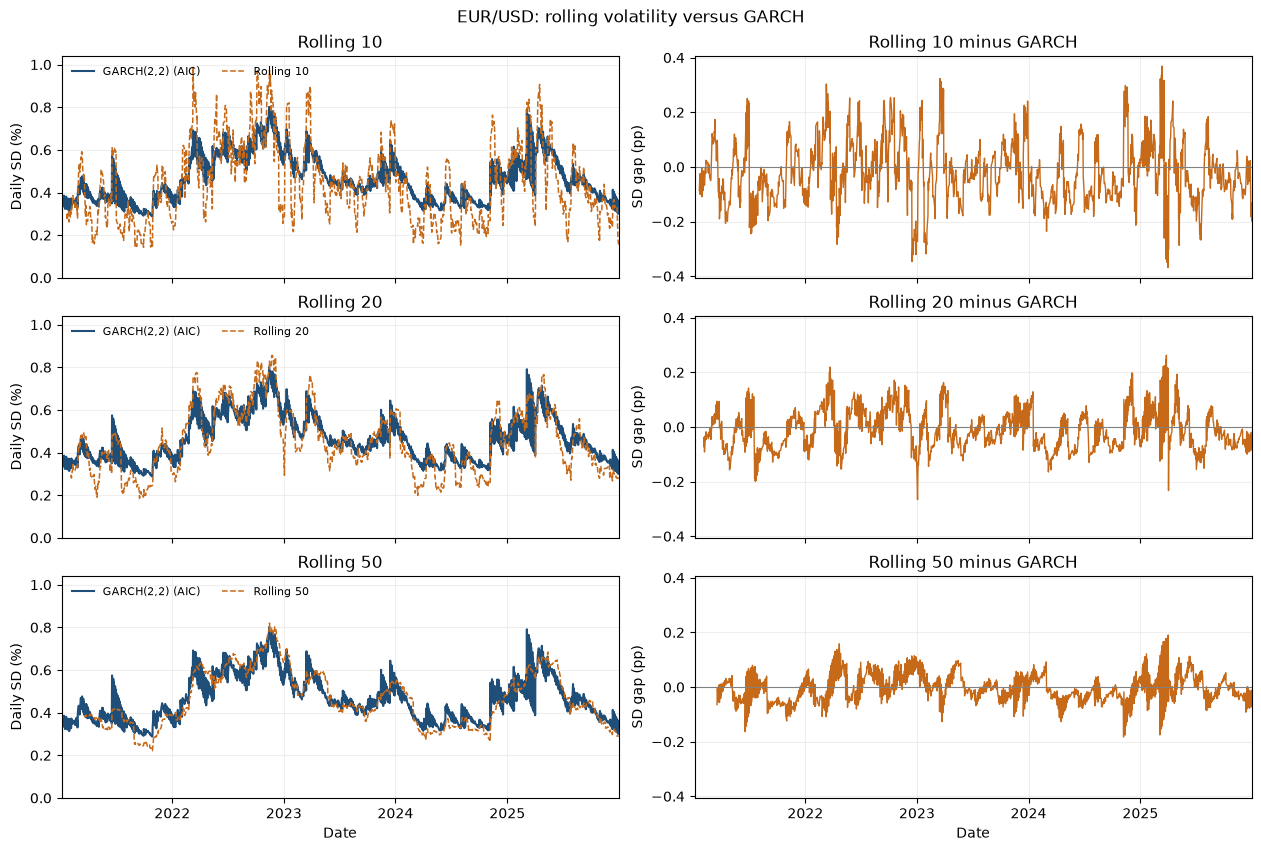

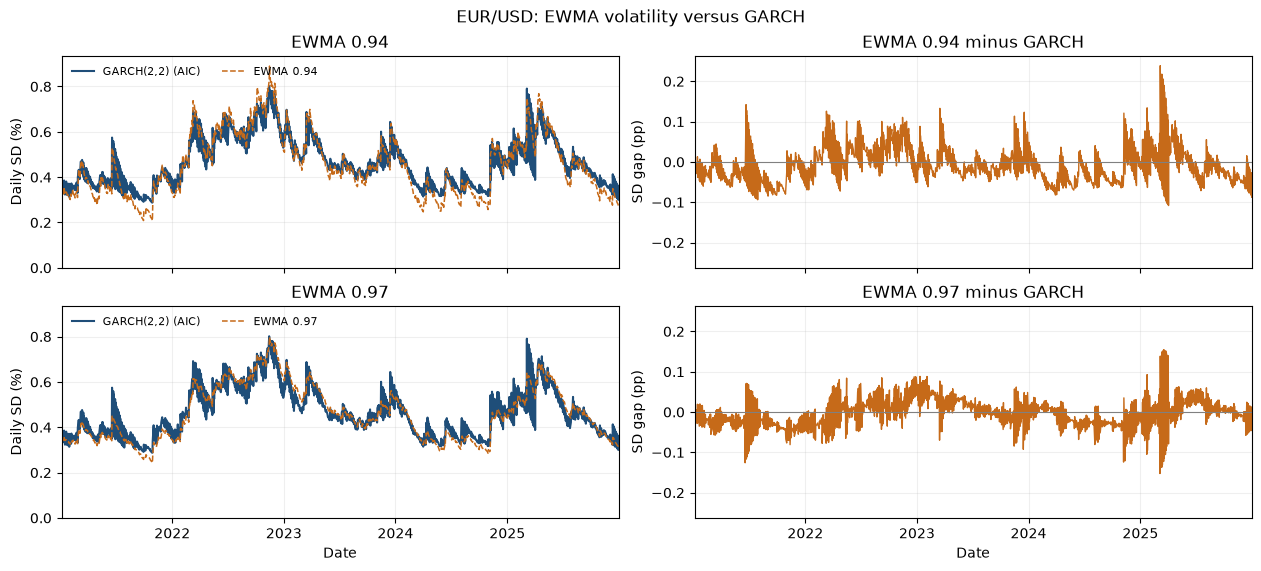

In [15]:
chosen_order = selected_variance_orders["AIC"]
chosen_fit = variance_fits[chosen_order]
rolling_sd = pd.DataFrame({f"Rolling {w}": returns.rolling(w, min_periods=w).std(ddof=1).shift(1)
                           for w in [10, 20, 50]})
epsilon = returns - chosen_fit.params["mu"]
ewma_variance = {}
for lam in [0.94, 0.97]:
    v = np.empty(len(returns))
    v[0] = BACKCAST
    for t in range(1, len(returns)):
        v[t] = lam * v[t - 1] + (1 - lam) * epsilon.iloc[t - 1]**2
    ewma_variance[lam] = pd.Series(v, index=returns.index)
ewma_sd = pd.DataFrame({f"EWMA {lam}": np.sqrt(v) for lam, v in ewma_variance.items()})
def plot_volatility_comparison(comparison, title):
    benchmark = chosen_fit.conditional_volatility
    fig, axes = plt.subplots(len(comparison.columns), 2,
                             figsize=(12.5, 2.8 * len(comparison.columns)),
                             sharex=True, sharey="col", squeeze=False, constrained_layout=True)
    sd_max = max(benchmark.max(), comparison.max().max())
    differences = comparison.sub(benchmark, axis=0)
    gap_bound = 1.1 * differences.abs().max().max()
    for row, name in enumerate(comparison.columns):
        ax, gap_ax = axes[row]
        ax.plot(benchmark.index, benchmark, color="#1F4E79", linewidth=1.5,
                label=f"{model_label(chosen_order)} (AIC)")
        ax.plot(comparison.index, comparison[name], color="#C66A19", linestyle="--",
                linewidth=1.1, label=name)
        ax.set(title=name, ylabel="Daily SD (%)", ylim=(0, 1.05 * sd_max))
        ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
        gap_ax.plot(differences.index, differences[name], color="#C66A19", linewidth=1)
        gap_ax.axhline(0, color="grey", linewidth=0.8)
        gap_ax.set(title=f"{name} minus GARCH", ylabel="SD gap (pp)",
                   ylim=(-gap_bound, gap_bound))
        for panel in [ax, gap_ax]:
            panel.set_xlim(returns.index[0], returns.index[-1])
            panel.xaxis.set_major_locator(mdates.YearLocator())
            panel.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
            panel.grid(alpha=0.2)
    for ax in axes[-1]:
        ax.set_xlabel("Date")
    fig.suptitle(title)
    plt.show()

plot_volatility_comparison(rolling_sd, "EUR/USD: rolling volatility versus GARCH")
plot_volatility_comparison(ewma_sd, "EUR/USD: EWMA volatility versus GARCH")


## Bootstrap comparison of GARCH orders

The comparison of the AIC-selected **GARCH(2,2)** with the smaller **GARCH(1,1)** uses
$LR=2(\ell_U-\ell_R)$. A standard chi-square reference is not generally
justified: setting nonnegative variance coefficients to zero puts the null
on a parameter boundary.

The **Gaussian parametric bootstrap** simulates 199 samples under the fitted
smaller model and refits both orders. The p-value compares their LR statistics
with the observed one, using a plus-one correction. Its Monte Carlo SE
accompanies the 5% decision; small differences near 5% are not decisive.

This approximate reference treats the observed orders as fixed. It omits
order-selection uncertainty and depends on the assumed shock distribution.
Each replication repeats variance initialisation and estimation.


In [16]:
BOOTSTRAP_REPLICATIONS = 199
BOOTSTRAP_SEED = 20261015
p_u, q_u = chosen_order
restricted_order = (max(0, p_u - 1), max(0, q_u - 1))
# With no shock lags, the stationary restricted variance is constant.
if restricted_order[0] == 0:
    restricted_order = (0, 0)
restricted_fit = variance_fits[restricted_order]

def nested_start(restricted, order):
    p, q = order
    omega = restricted.params.get("omega", restricted.params.get("sigma2"))
    return np.array([restricted.params["mu"], omega]
                    + [restricted.params.get(f"alpha[{i}]", 0.0) for i in range(1, p + 1)]
                    + [restricted.params.get(f"beta[{j}]", 0.0) for j in range(1, q + 1)])

def fit_unrestricted(values, restricted, initial_variance):
    attempts = []
    for start in [None, nested_start(restricted, chosen_order)]:
        try:
            attempts.append(fit_variance_model(values, chosen_order, initial_variance, start))
        except RuntimeError:
            pass
    if not attempts:
        raise RuntimeError("Both unrestricted optimisation starts failed.")
    result = max(attempts, key=lambda fit: fit.loglikelihood)
    if result.loglikelihood < restricted.loglikelihood - 1e-5:
        raise RuntimeError("Unrestricted likelihood is below its nested restriction.")
    return result

observed_unrestricted = fit_unrestricted(returns, restricted_fit, BACKCAST)
observed_lr = max(0.0, 2 * (observed_unrestricted.loglikelihood - restricted_fit.loglikelihood))
simulation_model = arch_model(None, mean="Constant", vol="Constant" if restricted_order[0] == 0 else "GARCH",
                                           p=max(1, restricted_order[0]), q=restricted_order[1], dist="normal", rescale=False)
simulation_model.distribution = Normal(seed=BOOTSTRAP_SEED)
bootstrap_lr, failed_attempts = [], 0
while len(bootstrap_lr) < BOOTSTRAP_REPLICATIONS:
    simulated = simulation_model.simulate(restricted_fit.params, nobs=len(returns) + PRE_SAMPLE_LENGTH, burn=500)["data"]
    simulated_backcast = float(simulated.iloc[:PRE_SAMPLE_LENGTH].var(ddof=0))
    simulated_sample = simulated.iloc[PRE_SAMPLE_LENGTH:].reset_index(drop=True)
    try:
        restricted = fit_variance_model(simulated_sample, restricted_order, simulated_backcast)
        unrestricted = fit_unrestricted(simulated_sample, restricted, simulated_backcast)
        bootstrap_lr.append(max(0.0, 2 * (unrestricted.loglikelihood - restricted.loglikelihood)))
    except RuntimeError:
        failed_attempts += 1
        if failed_attempts > 20:
            raise RuntimeError("Too many failed bootstrap optimisations: inspect the models.")
bootstrap_p = (1 + np.count_nonzero(np.asarray(bootstrap_lr) >= observed_lr)) / (BOOTSTRAP_REPLICATIONS + 1)
bootstrap_mcse = np.sqrt(bootstrap_p * (1 - bootstrap_p) / (BOOTSTRAP_REPLICATIONS + 1))
specification_comparison = pd.DataFrame({"LR statistic": [observed_lr], "Bootstrap p-value": [bootstrap_p],
    "Monte Carlo SE": [bootstrap_mcse], "Successful replications": [len(bootstrap_lr)],
    "Failed attempts": [failed_attempts],
    "Decision at 5%": ["Reject smaller model" if bootstrap_p < 0.05 else "Do not reject smaller model"]},
    index=[f"{model_label(chosen_order)} versus {model_label(restricted_order)}"])
display(specification_comparison.round(4))

,LR statistic,Bootstrap p-value,Monte Carlo SE,Successful replications,Failed attempts,Decision at 5%
"GARCH(2,2) versus GARCH(1,1)",9.1458,0.01,0.007,199,0,Reject smaller model


## One- and two-step volatility forecasts

From **31 December 2025**, the models forecast conditional variance for the next
one and two **observed quotations**. Taking square roots gives volatility forecasts.
These historical-origin point forecasts are neither prediction intervals
nor a verified out-of-sample exercise.

The first GARCH(1,1) forecast uses the last squared residual and filtered
variance. Later forecasts replace unknown squared shocks by their conditional
expectations. Higher-order models retain additional lags, so adjustment need
not be monotone. Parameter and order uncertainty are omitted.


In [17]:
forecast_rows = []
variance_forecasts = {}
for order in sorted(set(selected_variance_orders.values())):
    fit = variance_fits[order]
    future_variance = fit.forecast(horizon=2, method="analytic", reindex=False).residual_variance.iloc[-1]
    variance_forecasts[order] = future_variance.to_numpy()
    criteria = ", ".join(c for c, selected in selected_variance_orders.items() if selected == order)
    forecast_rows.append({"Model": model_label(order), "Selected by": criteria,
                          "h=1 SD (%)": np.sqrt(future_variance.iloc[0]),
                          "h=2 SD (%)": np.sqrt(future_variance.iloc[1])})
volatility_forecasts = pd.DataFrame(forecast_rows).set_index("Model")
display(volatility_forecasts.round(4))

,Selected by,h=1 SD (%),h=2 SD (%)
Model,,,
"GARCH(1,1)",BIC,0.3300,0.3322
"GARCH(2,2)",AIC,0.2994,0.3519
